<a href="https://colab.research.google.com/github/nandameneguel/Nandameneguel/blob/main/E-Commerce%20Olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**E-commerce Olist**

##**Introdução**
A Olist é uma empresa brasileira de tecnologia, com um ecossistema completo de e-commerce que atua como um grande "agregador de marketplaces". Seu modelo de negócio conecta pequenos e médios lojistas aos maiores canais de venda online do país, como, por exemplo: Mercado Livre, Amazon, B2W. Por meio de um único contrato e de uma plataforma centralizada ao assumir a complexidade da gestão de catálogos, integração tecnológica, processamento de pagamentos, logística e atendimento ao cliente (SAC), a Olist permite que varejistas ganhem escala nacional rapidamente, enquanto a própria Olist consolida um inventário massivo e diversificado de produtos.

##**Descrição do Projeto**

O objetivo deste projeto é apresentar um relatório executivo direcionado a investidores e acionistas do setor de e-commerce, fundamentado na exploração de dados do Brazilian E-Commerce Public Dataset by Olist. O estudo diagnóstica a saúde da operação ponta a ponta, mapeando oportunidades estratégicas de crescimento comercial, eficiência logística e retenção de clientes para maximização da rentabilidade.


###**Link Olist**

**Base de dados da Olist:** https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

#**Importando bibliotecas**

In [9]:
# manipulação dos dados
import pandas as pd
import numpy as np

# visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

#**Crescimento e Receita**

Nesta etapa, exploramos a saúde financeira e a estabilidade da operação. No ecossistema de e-commerce, o crescimento não é medido apenas pelo volume bruto, mas pela qualidade e composição dessa receita. As análises e visualizações a seguir foram estruturadas para responder às principais perguntas de negócio através dos seguintes tópicos:

*   Evolução mensal de pedidos
*   Evolução da receita bruta
*   Análise de ticket médio
*   Top 10 categorias: Por Categorias, Volume de Vendas e Receita Bruta.

##**Evolução Mensal de Pedidos**

/tmp/ipykernel_2213/2292583461.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


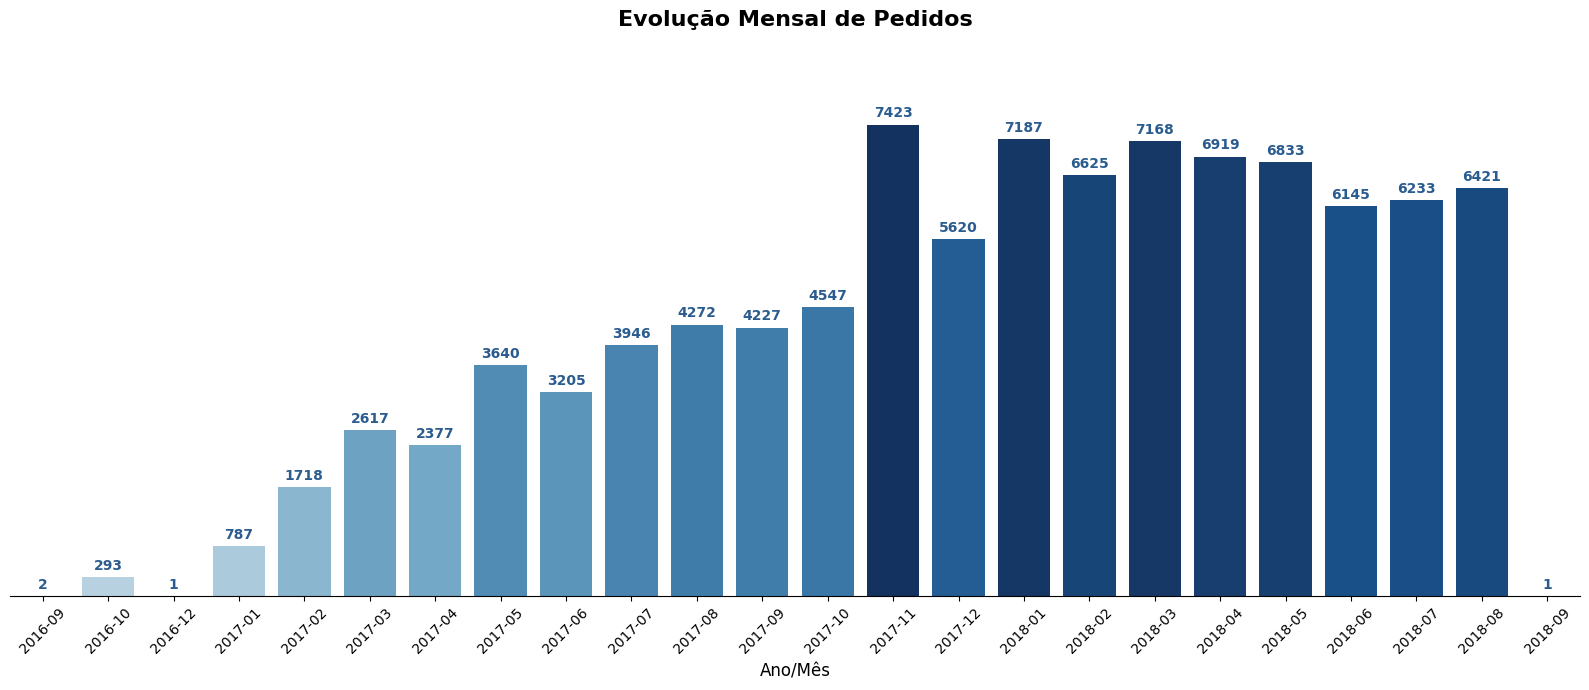

In [37]:
# 1. Leitura tabela de pedidos
df_orders = pd.read_csv('olist_orders_dataset.csv')

# 2. Filtragem de pedidos válidos.
# Remoção de pedidos: Cancelados e indisponíveis
df_orders_valid = df_orders[~df_orders['order_status'].isin(['canceled', 'unavailable'])].copy()
df_orders_valid['order_purchase_timestamp'] = pd.to_datetime(df_orders_valid['order_purchase_timestamp'])
df_orders_valid['ano_mes'] = df_orders_valid['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 3. Contagem de pedidos por mês
# Ordenação cronologicamente para o eixo X
pedidos_por_mes = df_orders_valid.groupby('ano_mes')['order_id'].count().reset_index()
pedidos_por_mes.columns = ['Mês/Ano', 'Total de Pedidos']
pedidos_por_mes = pedidos_por_mes.sort_values('Mês/Ano')

# 4. Criação de gráfico
plt.figure(figsize=(16, 7))

# Utilizando tonalidades de azul em proporção a quantidade de pedidos efetuados, utilizando a paleta Blues.
norm = plt.Normalize(vmin=-(pedidos_por_mes['Total de Pedidos'].max() * 0.4), vmax=pedidos_por_mes['Total de Pedidos'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in pedidos_por_mes['Total de Pedidos']]

ax = sns.barplot(
    data=pedidos_por_mes,
    x='Mês/Ano',
    y='Total de Pedidos',
    palette=cores,
    legend=False
)

# 5. Adição de rótulos de dados
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10, fmt='%d', fontweight='bold', color='#2b5c8f')

# 6. Personalização e limepza de visual.
plt.title('Evolução Mensal de Pedidos', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Ano/Mês', fontsize=12)

# Limpeza do Eixo y
ax.set_ylabel('')
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# 7. Aumento de teto do gráfico para que a exibição do rótulo de quantidade permaneça no gráfico.
plt.ylim(0, pedidos_por_mes['Total de Pedidos'].max() * 1.15)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##**Evolução de Receita Bruta por Ano**

/tmp/ipykernel_2213/3177304134.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


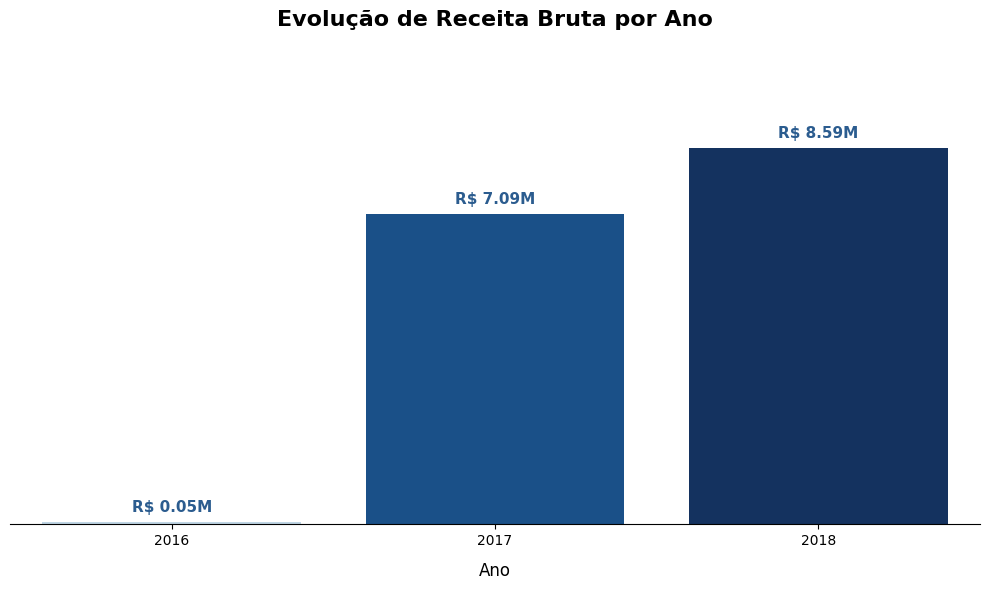

In [72]:
# 1. Utilizando tabela de pedidos que contém a data tratada e extraindo o ano.
df_orders['order_purchase_timestamp'] = pd.to_datetime(df_orders['order_purchase_timestamp'])
df_orders['ano'] = df_orders['order_purchase_timestamp'].dt.year

# 2. Merge direto da tabela de pagamentos (payments) com o ano do pedido.
df_receita_anual = pd.merge(df_payments, df_orders[['order_id', 'ano', 'order_status']], on='order_id', how='inner')

# 3. Filtragem de pedidos válidos.
# Remoção de pedidos: Cancelados e indisponíveis.
df_receita_anual = df_receita_anual[~df_receita_anual['order_status'].isin(['canceled', 'unavailable'])]

# 4. Agrupando por pedido e ano, em seguida somando por ano para obter o total da receita bruta.
valor_por_pedido_ano = df_receita_anual.groupby(['order_id', 'ano'])['payment_value'].sum().reset_index()
receita_anual = valor_por_pedido_ano.groupby('ano')['payment_value'].sum().reset_index()
receita_anual.columns = ['Ano', 'Receita_Total']
receita_anual = receita_anual.sort_values('Ano')

# 5. Criando Gráfico de Colunas.
plt.figure(figsize=(10, 6))

# Utilizando tons em azul para representar a logomarca da Olist.
norm = plt.Normalize(vmin=-(receita_anual['Receita_Total'].max() * 0.4), vmax=receita_anual['Receita_Total'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in receita_anual['Receita_Total']]

# Plotando o barplot
ax = sns.barplot(
    data=receita_anual,
    x='Ano',
    y='Receita_Total',
    palette=cores
)

# 6. Adição de rótulos
for p in ax.patches:
    height = p.get_height()
    val_milhoes = height * 1e-6
    ax.annotate(f"R$ {val_milhoes:.2f}M",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=11, fontweight='bold', color='#2b5c8f')

# 7. Personalização e Limpeza de Visual.
plt.title('Evolução de Receita Bruta por Ano', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Ano', fontsize=12, labelpad=10)

# Remoção do eixo y e bordas.
ax.set_ylabel('')
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

#  Aumento de teto do gráfico para que a exibição do rótulo de valores permaneça no gráfico.
plt.ylim(0, receita_anual['Receita_Total'].max() * 1.25)

plt.tight_layout()
plt.show()

##**Análise de ticket médio por mês**

💰 O Ticket Médio Geral da Olist é: 160.27 reais


/tmp/ipykernel_2213/4011412341.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


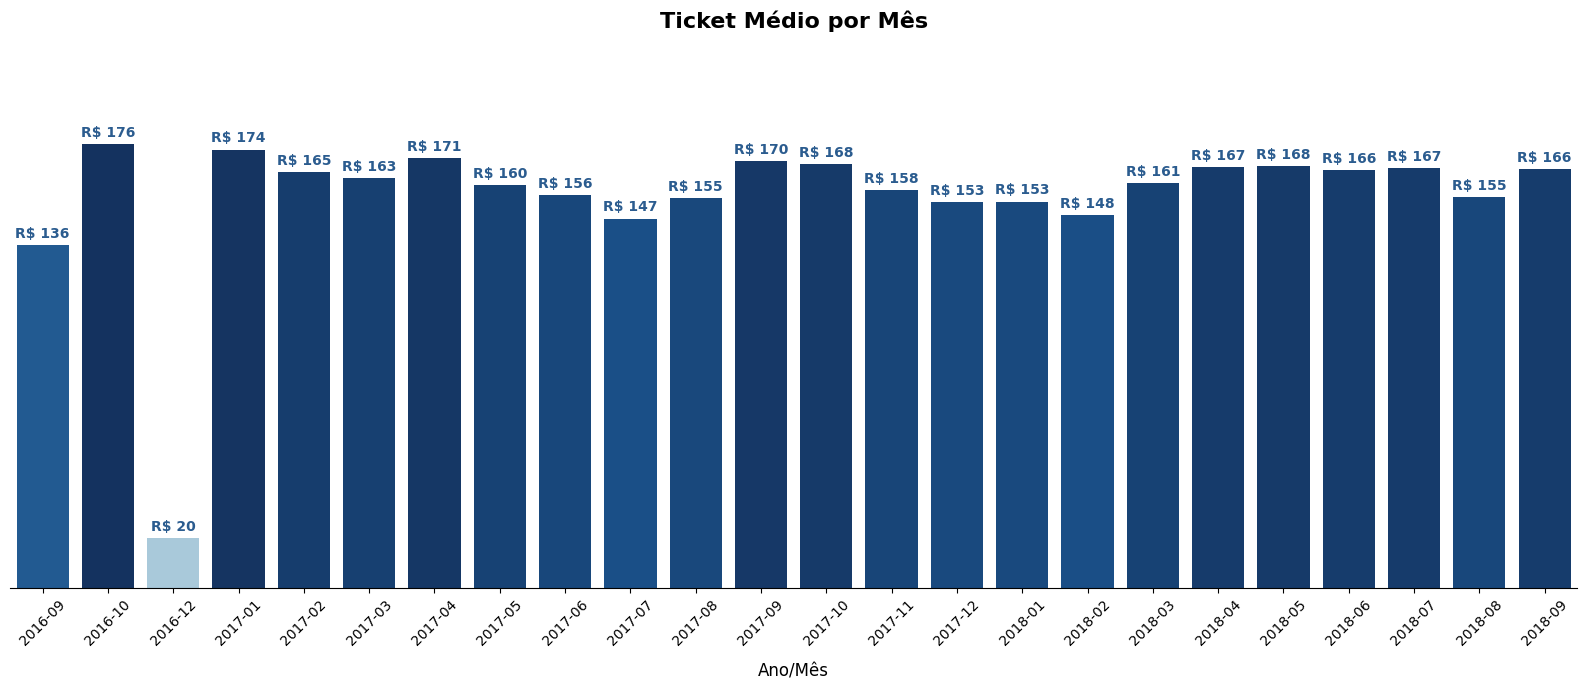

In [39]:
# 0. Leitura da tabela payments
df_payments = pd.read_csv('olist_order_payments_dataset.csv')
df_receita = pd.merge(df_orders_valid, df_payments, on='order_id', how='inner')

# 1. Agrupando os pagamentos por pedido.
valor_por_pedido = df_receita.groupby(['order_id', 'ano_mes'])['payment_value'].sum().reset_index()

# 2. Cálculo de ticket médio por mês.
ticket_mensal = valor_por_pedido.groupby('ano_mes')['payment_value'].mean().reset_index()

# 3. Cálculo de ticket médio geral.
ticket_geral = valor_por_pedido['payment_value'].mean()
print(f"💰 O Ticket Médio Geral da Olist é: {ticket_geral:.2f} reais")

# 4. Criação do gráfico
plt.figure(figsize=(16, 7))

# Utilizando tonalidades de azul em proporção a valores.
norm = plt.Normalize(vmin=-(ticket_mensal['payment_value'].max() * 0.4), vmax=ticket_mensal['payment_value'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
colors = [sm.to_rgba(val) for val in ticket_mensal['payment_value']]

# Utilizando o barplot com a paleta baseada no valor
ax = sns.barplot(
    data=ticket_mensal,
    x='ano_mes',
    y='payment_value',
    palette=colors
)

# 5. Criando os textos com "R$" e colocando no topo de cada coluna
for container in ax.containers:
    ax.bar_label(container, fmt="R$ %.0f", padding=3, fontsize=10, fontweight='bold', color='#2b5c8f')

# 6. Personalização e limpeza
plt.title('Ticket Médio por Mês', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Ano/Mês', fontsize=12, labelpad=10)

# Remoção do Eixo y e bordas
ax.set_ylabel('')
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Aumento de teto do gráfico para que a exibição do rótulo de valores permaneçam no gráfico.
plt.ylim(0, ticket_mensal['payment_value'].max() * 1.2)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##**Top 10 Categorias que Mais Geram Receita**

/tmp/ipykernel_2213/1390134736.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=top10_cat_receita, x='price', y='product_category_name', palette=cores)


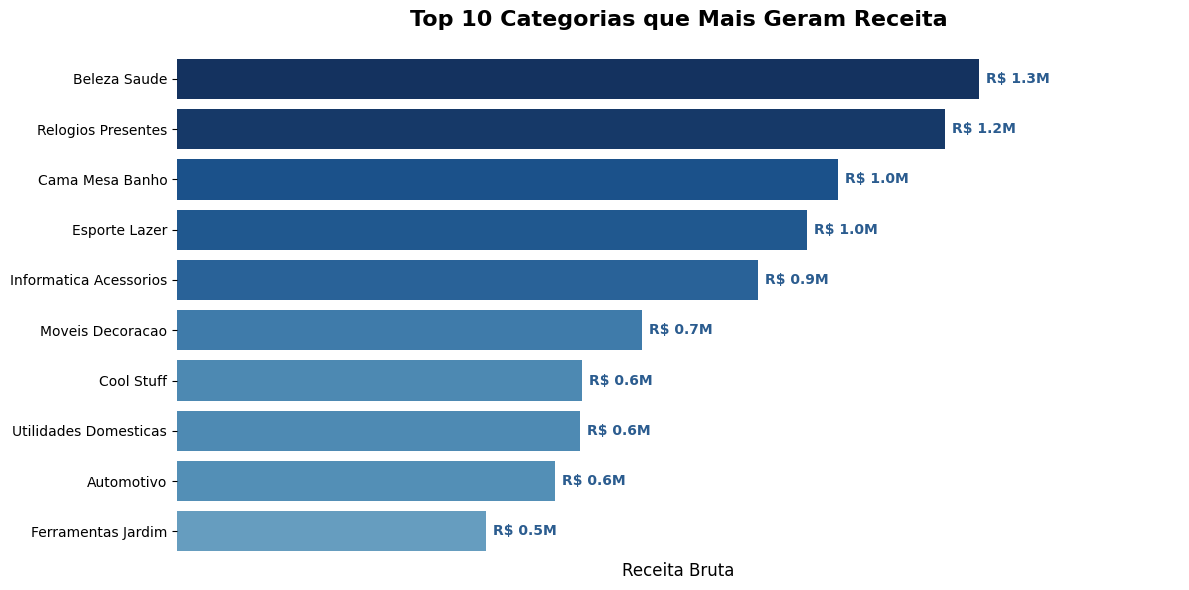

In [40]:
# 1. Leitura das tabelas items e products.
df_items = pd.read_csv('olist_order_items_dataset.csv')
df_products = pd.read_csv('olist_products_dataset.csv')

# 2. Merge entre as tabelas items e products.
df_prod_items = pd.merge(df_items, df_products, on='product_id', how='inner')

# 3. Efetuando limpeza e melhoria no nome das categorias.
df_prod_items['product_category_name'] = df_prod_items['product_category_name'].str.replace('_', ' ').str.title()

# Agrupando por categoria e somando o preço
receita_categoria = df_prod_items.groupby('product_category_name')['price'].sum().reset_index()
top10_cat_receita = receita_categoria.sort_values(by='price', ascending=False).head(10)

plt.figure(figsize=(12, 6))

# Utilizando tonalidades de azul em proporção a valores de preços.
norm = plt.Normalize(vmin=-(top10_cat_receita['price'].max() * 0.4), vmax=top10_cat_receita['price'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in top10_cat_receita['price']]

ax1 = sns.barplot(data=top10_cat_receita, x='price', y='product_category_name', palette=cores)

# Adição de rótulos
for p in ax1.patches:
    width = p.get_width()
    val_milhoes = width * 1e-6
    ax1.annotate(f"R$ {val_milhoes:.1f}M",
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=10, fontweight='bold', color='#2b5c8f')

plt.title('Top 10 Categorias que Mais Geram Receita', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Receita Bruta', fontsize=12)
plt.ylabel('')

# Limpeza de visual
ax1.set_xticks([])
ax1.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
plt.xlim(0, top10_cat_receita['price'].max() * 1.25)

plt.tight_layout()
plt.show()

##**Top 10 produtos mais vendidos por volume**

/tmp/ipykernel_2213/3820396352.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=top10_prod_volume, x='Volume_Vendas', y='Nome_Exibicao', palette=cores)


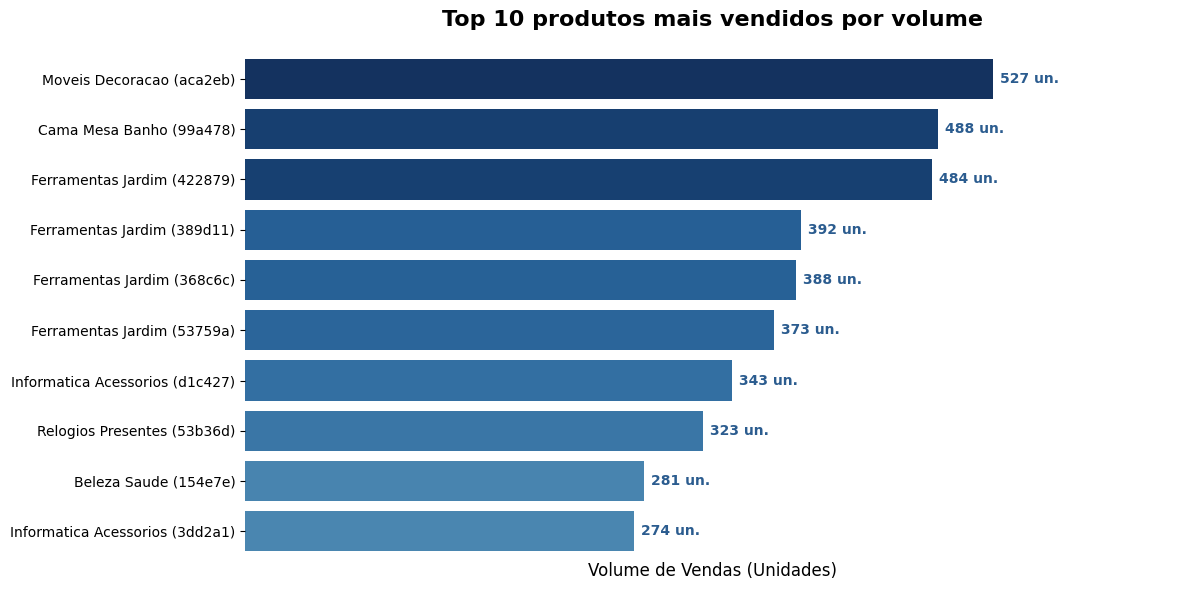

In [73]:
# 1. Agrupando por produto e categoria para contar quantas vezes foi vendido.
volume_produto = df_prod_items.groupby(['product_id', 'product_category_name'])['order_id'].count().reset_index()
volume_produto.columns = ['product_id', 'Categoria', 'Volume_Vendas']

# 2. Coletando os 10 mais vendidos
top10_prod_volume = volume_produto.sort_values(by='Volume_Vendas', ascending=False).head(10)

# 3. Concatenando Categoria + Início do ID.
top10_prod_volume['Nome_Exibicao'] = top10_prod_volume['Categoria'] + " (" + top10_prod_volume['product_id'].str[:6] + ")"

plt.figure(figsize=(12, 6))

# Utilizando tonalidades de azul em proporção a valores de vendas.
norm = plt.Normalize(vmin=-(top10_prod_volume['Volume_Vendas'].max() * 0.4), vmax=top10_prod_volume['Volume_Vendas'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in top10_prod_volume['Volume_Vendas']]
ax2 = sns.barplot(data=top10_prod_volume, x='Volume_Vendas', y='Nome_Exibicao', palette=cores)

# Adição de rótulos
for p in ax2.patches:
    width = p.get_width()
    ax2.annotate(f"{int(width)} un.",
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=10, fontweight='bold', color='#2b5c8f')

plt.title('Top 10 produtos mais vendidos por volume', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Volume de Vendas (Unidades)', fontsize=12)
plt.ylabel('')

# Limpeza visual
ax2.set_xticks([])
ax2.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
plt.xlim(0, top10_prod_volume['Volume_Vendas'].max() * 1.25)

plt.tight_layout()
plt.show()

##**Top 10 Estados que Mais Geram Receita Bruta**

/tmp/ipykernel_2213/299403946.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top10_uf, x='Receita', y='Estado', palette=cores)


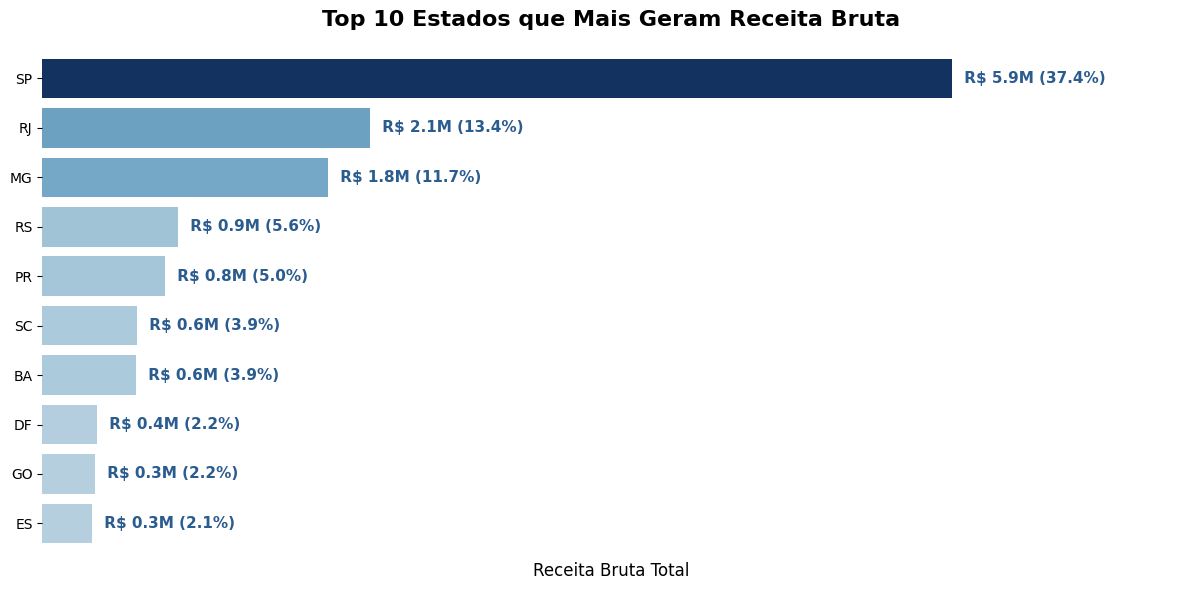

In [44]:
# 1. Leitura das tabelas orders, customers e payments.
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_customers = pd.read_csv('olist_customers_dataset.csv')
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

# 2. Filtragem de pedidos válidos.
# Remoção de pedidos: Cancelados e indisponíveis.
df_validos = df_orders[~df_orders['order_status'].isin(['canceled', 'unavailable'])].copy()

# 3. Merge de Pedidos, Pagamentos (Receita) e Clientes (para pegar a UF)
df_receita_uf = pd.merge(df_validos, df_payments, on='order_id', how='inner')
df_receita_uf = pd.merge(df_receita_uf, df_customers[['customer_id', 'customer_state']], on='customer_id', how='inner')

# 4. Agrupando e somando a receita total por Estado (UF).
faturamento_uf = df_receita_uf.groupby('customer_state')['payment_value'].sum().reset_index()
faturamento_uf.columns = ['Estado', 'Receita']

# Coletando o Top 10 Estados que mais faturam e ordenando do maior para o menor
top10_uf = faturamento_uf.sort_values(by='Receita', ascending=False).head(10).reset_index(drop=True)

# 5. Calculando o percentual de participação de cada Estado em relação ao total geral.
total_geral_brasil = faturamento_uf['Receita'].sum()
top10_uf['Percentual'] = (top10_uf['Receita'] / total_geral_brasil) * 100

# 6. Desenhando o Gráfico de Barras Horizontais.
plt.figure(figsize=(12, 6))

## Utilizando tonalidades de azul em proporção a valores da receita.
norm = plt.Normalize(vmin=-(top10_uf['Receita'].max() * 0.4), vmax=top10_uf['Receita'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in top10_uf['Receita']]

ax = sns.barplot(data=top10_uf, x='Receita', y='Estado', palette=cores)

# 7. Adição de Rótulos.
for p in ax.patches:
    width = p.get_width()
    val_milhoes = width * 1e-6
    match_row = top10_uf[top10_uf['Receita'] == width]
    if not match_row.empty:
        perc = match_row['Percentual'].values[0]
        label_texto = f" R$ {val_milhoes:.1f}M ({perc:.1f}%)"
    else:
        label_texto = f" R$ {val_milhoes:.1f}M"

    ax.annotate(label_texto,
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(5, 0),
                textcoords='offset points',
                fontsize=11, fontweight='bold', color='#2b5c8f')

# 8. Efetuação limpeza e perfeiçoamento.
plt.title('Top 10 Estados que Mais Geram Receita Bruta', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Receita Bruta Total', fontsize=12, labelpad=10)
plt.ylabel('')

# Remoção do eixo X e as bordas.
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
plt.xlim(0, top10_uf['Receita'].max() * 1.25)

plt.tight_layout()
plt.show()

#**Logística e SLA**

Nesta etapa, mapeamos a esteira operacional e a eficiência de entrega da plataforma. No ecossistema de e-commerce, a logística não atua apenas como um centro de custo, mas como um pilar decisivo para a conversão de vendas e retenção de clientes. Avaliar o tempo de trânsito e o cumprimento das promessas de prazo é fundamental para identificar gargalos operacionais e atritos na jornada de compra. As análises e visualizações a seguir foram estruturadas para mapear a malha logística através dos seguintes tópicos:

* Tempo médio de cada etapa logística.
* Tempo médio de entregas.
* Mapa de calor de desempenho por região.

##**Tempo Médio de Cada Etapa Logística**

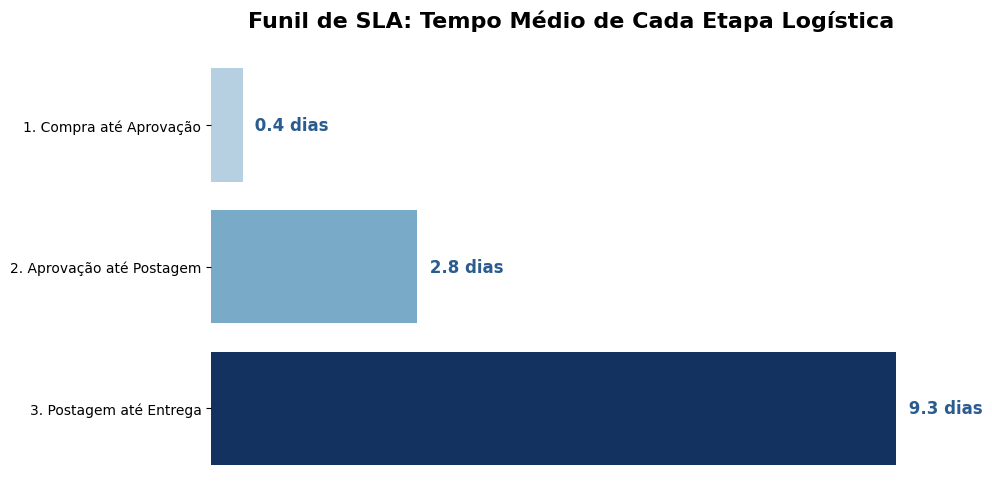

In [71]:
# 1. Carregando tabela orders.
df_orders = pd.read_csv('olist_orders_dataset.csv')

# 2. Filtro: Para calcular o funil completo, precisamos apenas dos pedidos 'delivered' (entregues)
df_entregues = df_orders[df_orders['order_status'] == 'delivered'].copy()

# 3. Convertendo as 4 colunas de data para o formato datetime do Python
colunas_data = ['order_purchase_timestamp', 'order_approved_at',
                'order_delivered_carrier_date', 'order_delivered_customer_date']

for col in colunas_data:
    df_entregues[col] = pd.to_datetime(df_entregues[col])

# 4. Calculando o tempo exato (em DIAS) de cada etapa do funil
# A fórmula dt.total_seconds() / 86400 converte o tempo perfeitamente, considerando até as horas (12h = 0.5 dias)
df_entregues['1. Compra até Aprovação'] = (df_entregues['order_approved_at'] - df_entregues['order_purchase_timestamp']).dt.total_seconds() / 86400
df_entregues['2. Aprovação até Postagem'] = (df_entregues['order_delivered_carrier_date'] - df_entregues['order_approved_at']).dt.total_seconds() / 86400
df_entregues['3. Postagem até Entrega'] = (df_entregues['order_delivered_customer_date'] - df_entregues['order_delivered_carrier_date']).dt.total_seconds() / 86400

# 5. Calculando a MÉDIA de dias que cada etapa costuma levar
medias_sla = df_entregues[['1. Compra até Aprovação', '2. Aprovação até Postagem', '3. Postagem até Entrega']].mean().reset_index()
medias_sla.columns = ['Etapa', 'Dias']

# 6. Construindo o Visual do Funil (Gráfico de Barras Horizontais)
plt.figure(figsize=(10, 5))

# Usando a cor laranja (#f39c12) para a trilha de Logística
norm = plt.Normalize(vmin=-(medias_sla['Dias'].max() * 0.4), vmax=medias_sla['Dias'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in medias_sla['Dias']]

ax = sns.barplot(data=medias_sla, x='Dias', y='Etapa', palette=cores, hue='Etapa', legend=False)

# 7. Adicionando os Rótulos (Data Labels) com o sufixo "dias"
for container in ax.containers:
    ax.bar_label(container, fmt=" %.1f dias", padding=5, fontsize=12, fontweight='bold', color='#2b5c8f')

# 8. Personalização e Limpeza Executiva (Padrão Power BI Premium)
plt.title('Funil de SLA: Tempo Médio de Cada Etapa Logística', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('')
plt.ylabel('')

# Removendo absolutamente tudo do eixo X e todas as bordas
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

##**Tempo médio de entregas**

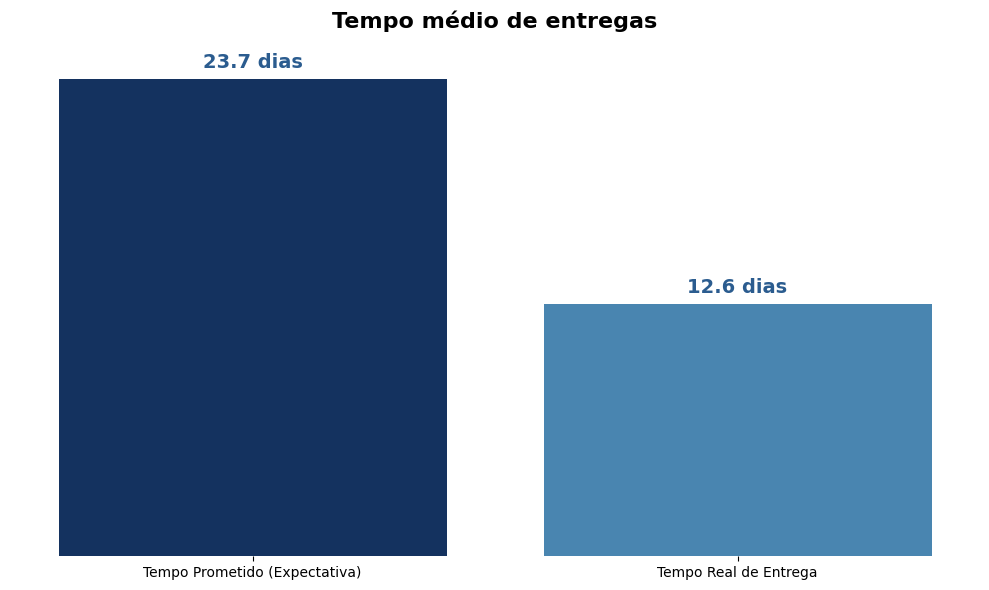

In [79]:
# 1. Coletando apenas pedidos entregues
df_entregues = df_orders[df_orders['order_status'] == 'delivered'].copy()

# 2. Convertendo as datas fundamentais para datetime
df_entregues['order_purchase_timestamp'] = pd.to_datetime(df_entregues['order_purchase_timestamp'])
df_entregues['order_delivered_customer_date'] = pd.to_datetime(df_entregues['order_delivered_customer_date'])
df_entregues['order_estimated_delivery_date'] = pd.to_datetime(df_entregues['order_estimated_delivery_date'])

# 3. Fazendo a matemática (Cálculo da Realidade vs Promessa em dias)
df_entregues['Tempo_Real'] = (df_entregues['order_delivered_customer_date'] - df_entregues['order_purchase_timestamp']).dt.total_seconds() / 86400
df_entregues['Tempo_Prometido'] = (df_entregues['order_estimated_delivery_date'] - df_entregues['order_purchase_timestamp']).dt.total_seconds() / 86400

# 4. Tirando a média geral
media_real = df_entregues['Tempo_Real'].mean()
media_prometida = df_entregues['Tempo_Prometido'].mean()

# 5. Criando a "tabelinha" para o gráfico
df_promessa = pd.DataFrame({
    'Métrica': ['Tempo Prometido (Expectativa)', 'Tempo Real de Entrega'],
    'Dias': [media_prometida, media_real]
})

# 6. Adição do Gráfico de Colunas
plt.figure(figsize=(10, 6))

# Utilizando tonalidades de azul em proporção a valores da entrega.
norm = plt.Normalize(vmin=-(df_promessa['Dias'].max() * 0.4), vmax=df_promessa['Dias'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in df_promessa['Dias']]

ax = sns.barplot(data=df_promessa, x='Métrica', y='Dias', palette=cores, hue='Métrica', legend=False)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f dias', padding=5, fontsize=14, fontweight='bold', color='#2b5c8f')

# 8. Personalização Limpa
plt.title('Tempo médio de entregas', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('')
plt.xlabel('')

ax.set_yticks([])
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)

plt.tight_layout()
plt.show()

##**Mapa de calor de desempenho por região**

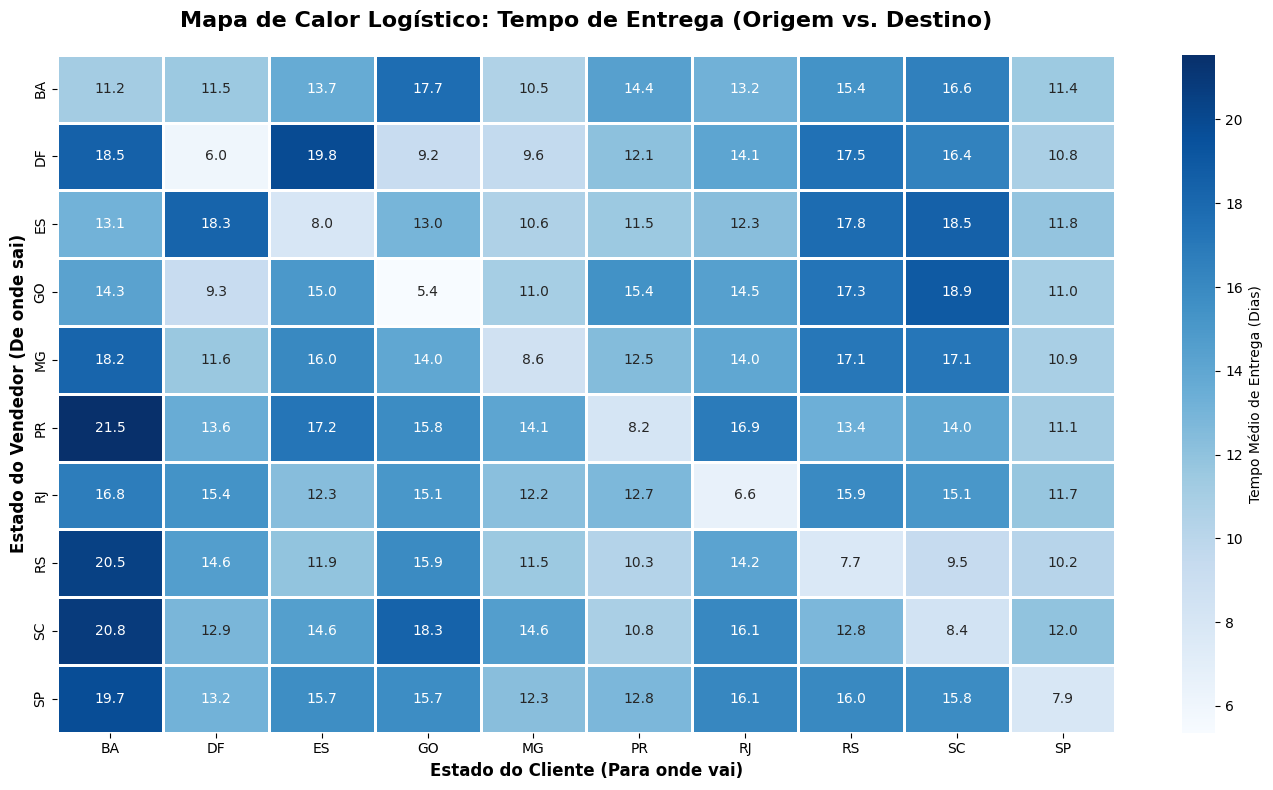

In [51]:
# 1. Leitura das tabelas orders, customers, items e sellers.
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_customers = pd.read_csv('olist_customers_dataset.csv')
df_items = pd.read_csv('olist_order_items_dataset.csv')
df_sellers = pd.read_csv('olist_sellers_dataset.csv')

# 2. Filtrando apenas os pedidos que foram de fato entregues
df_entregues = df_orders[df_orders['order_status'] == 'delivered'].copy()

# Calculando o Tempo Real de Entrega em dias (Da Compra até a Casa do Cliente)
df_entregues['order_purchase_timestamp'] = pd.to_datetime(df_entregues['order_purchase_timestamp'])
df_entregues['order_delivered_customer_date'] = pd.to_datetime(df_entregues['order_delivered_customer_date'])
df_entregues['Tempo_Entrega'] = (df_entregues['order_delivered_customer_date'] - df_entregues['order_purchase_timestamp']).dt.total_seconds() / 86400

# 3. Relacionando Pedido -> Cliente -> Item -> Vendedor
df_mapa = df_entregues[['order_id', 'customer_id', 'Tempo_Entrega']]
df_mapa = pd.merge(df_mapa, df_customers[['customer_id', 'customer_state']], on='customer_id', how='inner')
df_mapa = pd.merge(df_mapa, df_items[['order_id', 'seller_id']], on='order_id', how='inner')
df_mapa = pd.merge(df_mapa, df_sellers[['seller_id', 'seller_state']], on='seller_id', how='inner')

# 4. Selecionando os 10 Estados com mais volume.
top_10_estados = df_mapa['customer_state'].value_counts().head(10).index.tolist()

# Filtrando a tabela para conter apenas rotas entre esses 10 estados
df_filtrado = df_mapa[(df_mapa['customer_state'].isin(top_10_estados)) & (df_mapa['seller_state'].isin(top_10_estados))]

# 5. Criando a Matriz Pivot
# Linhas = Estado do Vendedor | Colunas = Estado do Cliente | Valores = Média do Tempo de Entrega
matriz_logistica = pd.pivot_table(df_filtrado,
                                  values='Tempo_Entrega',
                                  index='seller_state',
                                  columns='customer_state',
                                  aggfunc='mean')

# 6. Criando o Mapa de Calor
plt.figure(figsize=(14, 8))

# cmap="Blues" cria a paleta em tons de azul Olist.
# annot=True coloca o número do dia dentro do quadradinho
sns.heatmap(matriz_logistica, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={'label': 'Tempo Médio de Entrega (Dias)'},
            linewidths=1, linecolor='white')

# 7. Personalização (Nomes e Títulos)
plt.title('Mapa de Calor Logístico: Tempo de Entrega (Origem vs. Destino)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Estado do Vendedor (De onde sai)', fontsize=12, fontweight='bold')
plt.xlabel('Estado do Cliente (Para onde vai)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#**Comportamento e Pagamentos**

Nesta etapa, analisamos a jornada do consumidor, suas preferências financeiras e o impacto da qualidade do serviço na fidelização. No ecossistema de e-commerce, entender como o cliente paga e como ele avalia a experiência de compra é essencial para projetar o valor de tempo de vida do cliente e a sustentabilidade do negócio a longo prazo. As análises e visualizações a seguir foram estruturadas para mapear o perfil do usuário e os riscos da operação através dos seguintes tópicos:

*   Comportamento do consumidor ao efetuar compras.
*   Preferência de pagamento.
*   Comportamento de crédito.
*   Mapa de calor em dias e horários ao efetuar uma compra.





##**Comportamento do Consumidor**

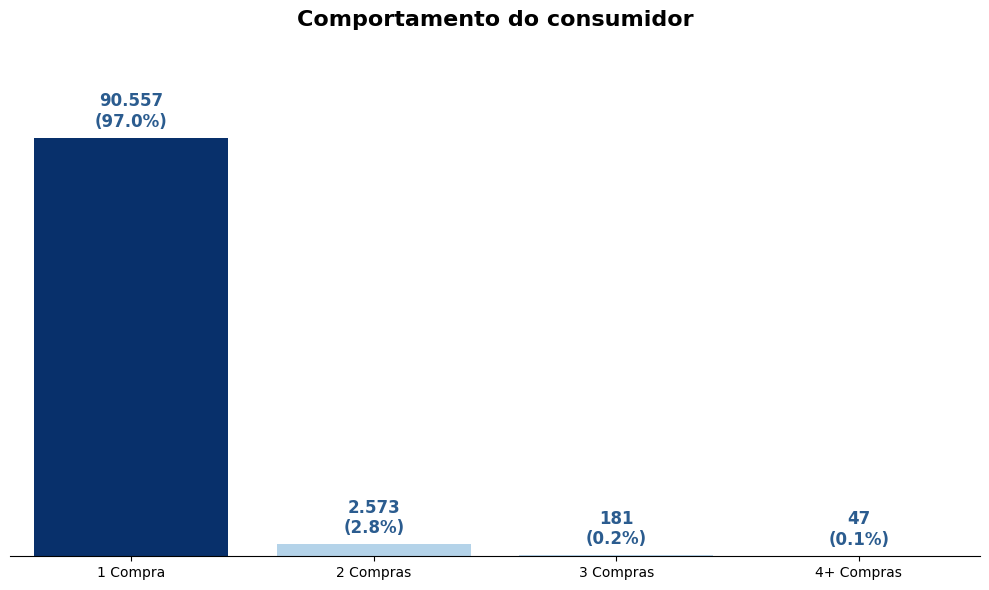

In [74]:
# 1. Leitura das tabelas orders e customers.
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_customers = pd.read_csv('olist_customers_dataset.csv')

df_entregues = df_orders[df_orders['order_status'] == 'delivered'].copy()
df_compras = pd.merge(df_entregues, df_customers[['customer_id', 'customer_unique_id']], on='customer_id')

# 2. Conta quantas compras cada cliente único fez.
compras_por_cliente = df_compras.groupby('customer_unique_id')['order_id'].count().reset_index()
compras_por_cliente.columns = ['customer_unique_id', 'qtd_compras']

# 3. Criar os Perfis de Compra.
def categorizar_compras(qtd):
    if qtd == 1: return '1 Compra'
    elif qtd == 2: return '2 Compras'
    elif qtd == 3: return '3 Compras'
    else: return '4+ Compras'

compras_por_cliente['Perfil de Compra'] = compras_por_cliente['qtd_compras'].apply(categorizar_compras)

# 4. Soma de total de clientes em cada perfil
perfil_clientes = compras_por_cliente['Perfil de Compra'].value_counts().reset_index()
perfil_clientes.columns = ['Perfil', 'Total de Clientes']

# Calculando o percentual para colocar no rótulo
total_geral = perfil_clientes['Total de Clientes'].sum()
perfil_clientes['Percentual'] = (perfil_clientes['Total de Clientes'] / total_geral) * 100

# Ordenar para o gráfico ficar lógico (1, 2, 3, 4+)
ordem = ['1 Compra', '2 Compras', '3 Compras', '4+ Compras']
perfil_clientes['Perfil'] = pd.Categorical(perfil_clientes['Perfil'], categories=ordem, ordered=True)
perfil_clientes = perfil_clientes.sort_values('Perfil')

# 5. Criando o Gráfico de Colunas.
plt.figure(figsize=(10, 6))

norm = plt.Normalize(vmin=-(perfil_clientes['Total de Clientes'].max() * 0.4), vmax=perfil_clientes['Total de Clientes'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in perfil_clientes['Total de Clientes']]

# Utilizando tonalidades de azul em proporção a valores de compra.
ax = sns.barplot(data=perfil_clientes, x='Perfil', y='Total de Clientes', color='#2b5c8f')
for p, cor in zip(ax.patches, cores):
    p.set_facecolor(cor)

# 6. Adicionando os rótulos de dados (Número e a Porcentagem)
labels = [f"{int(row['Total de Clientes']):,}\n({row['Percentual']:.1f}%)".replace(',', '.') for _, row in perfil_clientes.iterrows()]
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontsize=12, fontweight='bold', color='#2b5c8f')

# 7. Personalização
plt.title('Comportamento do consumidor', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('')
plt.ylabel('')

# Limpeza Padrão
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.ylim(0, perfil_clientes['Total de Clientes'].max() * 1.2)

plt.tight_layout()
plt.show()

##**Prefêrencia de Pagamento**

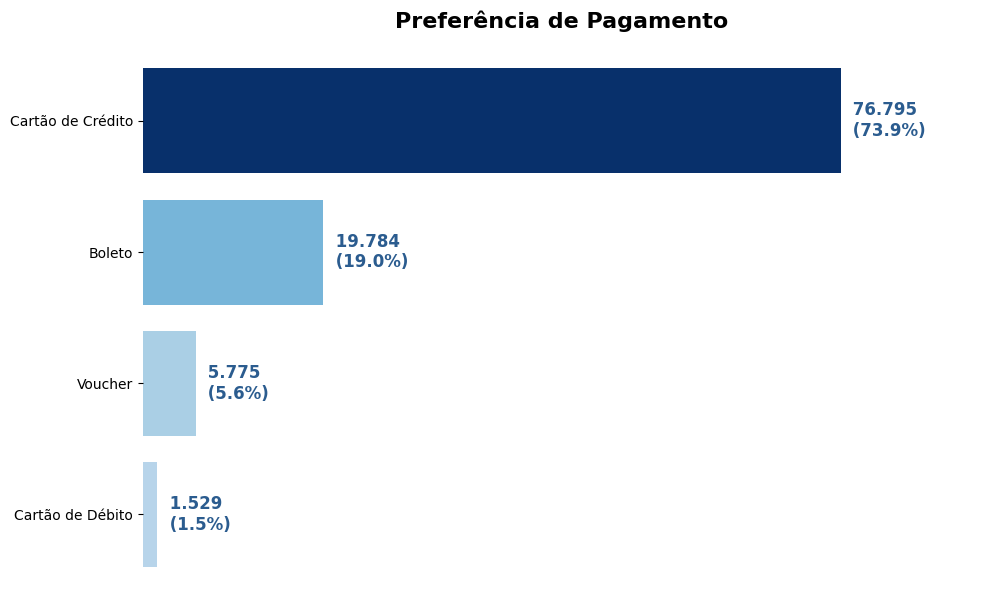

In [54]:
# 1. Leitura da tabela de payments
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

# 2. Traduzindo e limpando os nomes dos meios de pagamento
dicionario_pagamentos = {
    'credit_card': 'Cartão de Crédito',
    'boleto': 'Boleto',
    'voucher': 'Voucher',
    'debit_card': 'Cartão de Débito',
    'not_defined': 'Não Definido'
}
df_payments['payment_type'] = df_payments['payment_type'].map(dicionario_pagamentos)

# Removendo os 'Não Definidos'
df_pagamentos = df_payments[df_payments['payment_type'] != 'Não Definido'].copy()

# 3. Contando o volume de vezes que cada método foi usado
volume_pagamentos = df_pagamentos['payment_type'].value_counts().reset_index()
volume_pagamentos.columns = ['Tipo', 'Volume']

# 4. Calculando o percentual de participação de cada método
total_transacoes = volume_pagamentos['Volume'].sum()
volume_pagamentos['Percentual'] = (volume_pagamentos['Volume'] / total_transacoes) * 100

# 5. Adicionando visual de gráfico
plt.figure(figsize=(10, 6))

norm = plt.Normalize(vmin=-(volume_pagamentos['Volume'].max() * 0.4), vmax=volume_pagamentos['Volume'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in volume_pagamentos['Volume']]

ax = sns.barplot(data=volume_pagamentos, x='Volume', y='Tipo', color='#2b5c8f')
for p, cor in zip(ax.patches, cores):
    p.set_facecolor(cor)

# 6. Incluíndo o volume e a porcentagem no Rótulo de Dados
labels = [f" {int(row['Volume']):,}\n ({row['Percentual']:.1f}%)".replace(',', '.') for _, row in volume_pagamentos.iterrows()]
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontsize=12, fontweight='bold', color='#2b5c8f')

# 7. Limpeza Executiva e Personalização
plt.title('Preferência de Pagamento', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('')
plt.ylabel('')

# Removendo todas as linhas e o eixo X
ax.set_xticks([])
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)

# Aumentando o limite do eixo X para os rótulos não cortarem na direita
plt.xlim(0, volume_pagamentos['Volume'].max() * 1.2)

plt.tight_layout()
plt.show()

##**Comportamento de Crédito**

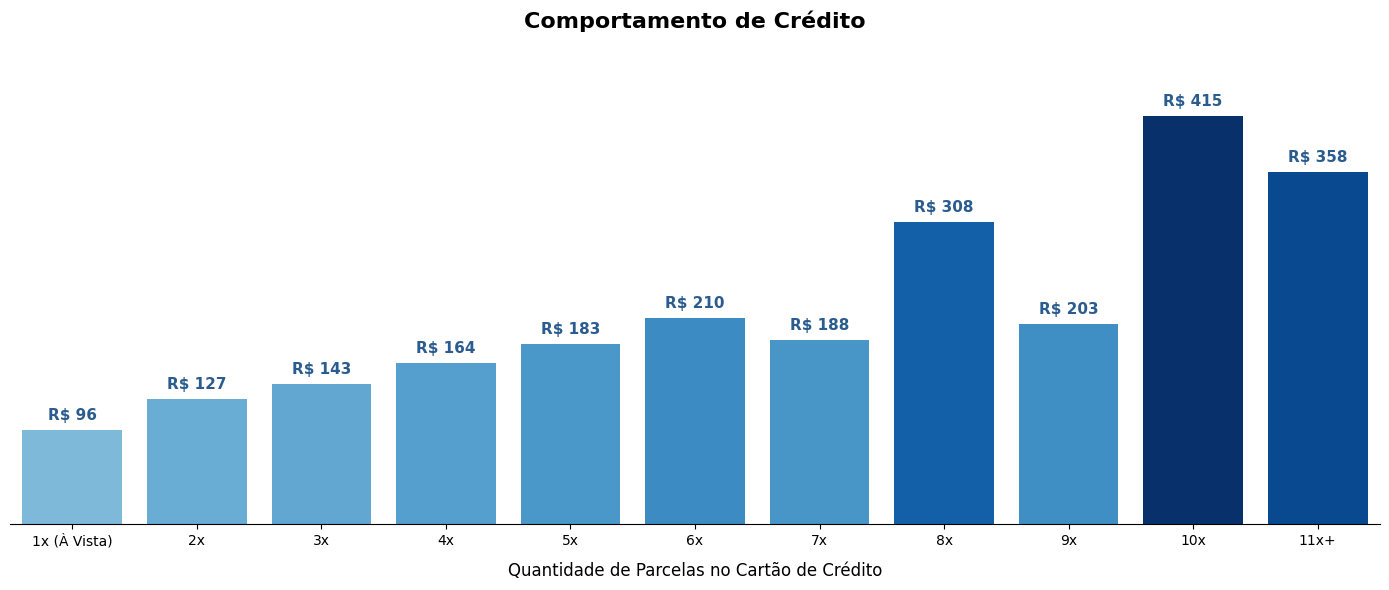

In [75]:
# 1. Leitura da tabela payments
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

# 2. Filtrando compras feitas com Cartão de Crédito
df_credito = df_payments[df_payments['payment_type'] == 'credit_card'].copy()

# 3. Agrupando parcelas muito altas
def agrupar_parcelas(parcela):
    if parcela == 1:
        return '1x (À Vista)'
    elif parcela <= 10:
        return f'{int(parcela)}x'
    else:
        return '11x+'

df_credito['Faixa de Parcelas'] = df_credito['payment_installments'].apply(agrupar_parcelas)

# 4. Calculando o Ticket Médio para cada faixa de parcela
ticket_por_parcela = df_credito.groupby('Faixa de Parcelas')['payment_value'].mean().reset_index()

# 5. Ordenando número de parcelas
ordem = ['1x (À Vista)', '2x', '3x', '4x', '5x', '6x', '7x', '8x', '9x', '10x', '11x+']
ticket_por_parcela['Faixa de Parcelas'] = pd.Categorical(ticket_por_parcela['Faixa de Parcelas'], categories=ordem, ordered=True)
ticket_por_parcela = ticket_por_parcela.sort_values('Faixa de Parcelas')

# 6. Criando o Visual
plt.figure(figsize=(14, 6))

norm = plt.Normalize(vmin=-(ticket_por_parcela['payment_value'].max() * 0.4), vmax=ticket_por_parcela['payment_value'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in ticket_por_parcela['payment_value']]

ax = sns.barplot(data=ticket_por_parcela, x='Faixa de Parcelas', y='payment_value', color='#2b5c8f')
for p, cor in zip(ax.patches, cores):
    p.set_facecolor(cor)

for container in ax.containers:
    ax.bar_label(container, fmt='R$ %.0f', padding=5, fontsize=11, fontweight='bold', color='#2b5c8f')

# 8. Personalização do gráfico
plt.title('Comportamento de Crédito', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Parcelas no Cartão de Crédito', fontsize=12, labelpad=10)
plt.ylabel('')

# A Mágica da Limpeza
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)

# Aumentando o teto do gráfico em 15% para os valores altos não cortarem
plt.ylim(0, ticket_por_parcela['payment_value'].max() * 1.15)

plt.tight_layout()
plt.show()

##**Mapa de Calor de Dias e Horários para efetuar compras**

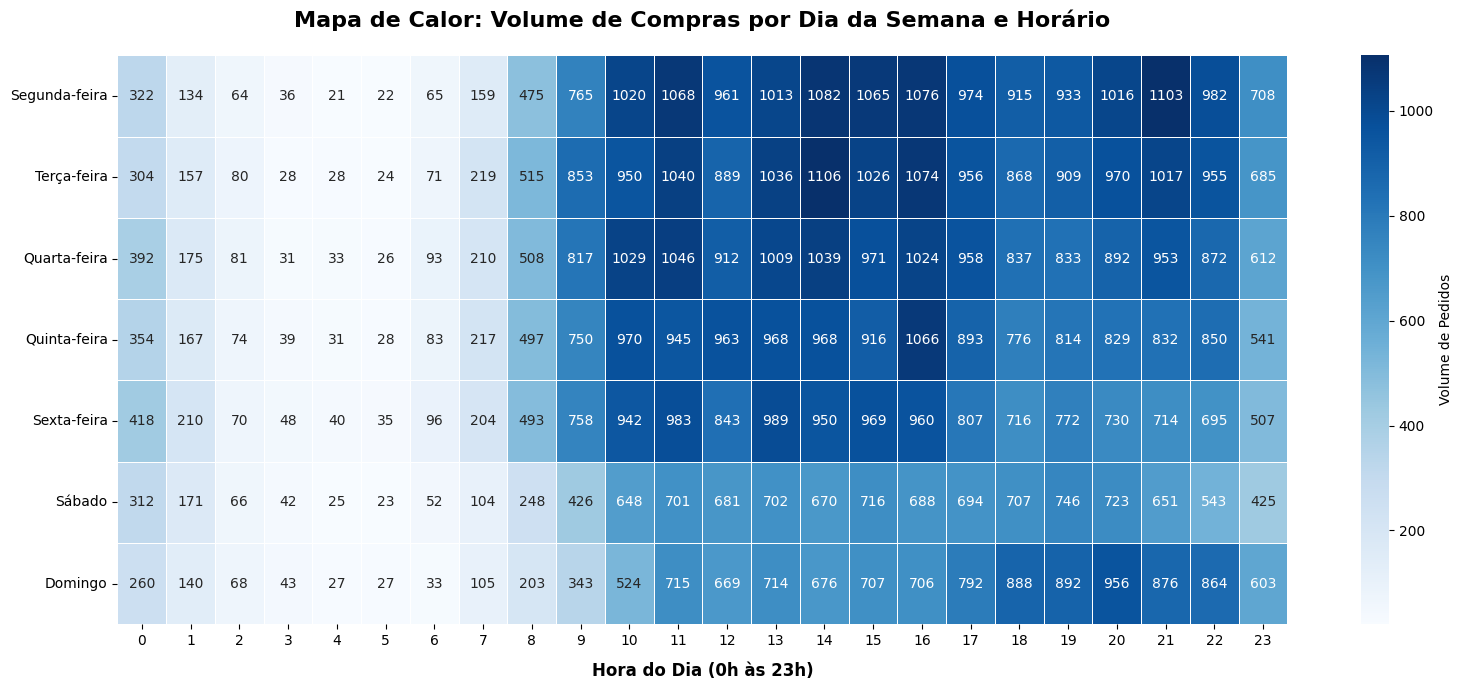

In [76]:
# 1. Leitura da tabela de pedidos
df_orders = pd.read_csv('olist_orders_dataset.csv')

# 2. Filtrar apenas pedidos válidos (removendo cancelados e indisponíveis)
df_orders_valid = df_orders[~df_orders['order_status'].isin(['canceled', 'unavailable'])].copy()

# 3. Converter a coluna de data para datetime
df_orders_valid['order_purchase_timestamp'] = pd.to_datetime(df_orders_valid['order_purchase_timestamp'])

# 4. Extrair o Dia da Semana e a Hora do Dia
dias_map = {
    0: 'Segunda-feira',
    1: 'Terça-feira',
    2: 'Quarta-feira',
    3: 'Quinta-feira',
    4: 'Sexta-feira',
    5: 'Sábado',
    6: 'Domingo'
}

df_orders_valid['Dia_Semana'] = df_orders_valid['order_purchase_timestamp'].dt.dayofweek.map(dias_map)
df_orders_valid['Hora'] = df_orders_valid['order_purchase_timestamp'].dt.hour

# Ordem cronológica correta para os dias da semana no eixo Y
ordem_dias = [
    'Segunda-feira', 'Terça-feira', 'Quarta-feira',
    'Quinta-feira', 'Sexta-feira', 'Sábado', 'Domingo'
]

# 5. Criando a Tabela Pivot para o Heatmap (Linhas = Dias, Colunas = Horas 0 a 23)
matriz_horarios = pd.pivot_table(df_orders_valid,
                                 values='order_id',
                                 index='Dia_Semana',
                                 columns='Hora',
                                 aggfunc='count',
                                 fill_value=0)

# Reindexando para manter a ordem lógica dos dias da semana
matriz_horarios = matriz_horarios.reindex(ordem_dias)

# 6. Desenhando o Mapa de Calor (Heatmap)
plt.figure(figsize=(16, 7))

# Utilizando tonalidades de azul e inserindo annot=True com fmt="d" para mostrar os números inteiros
sns.heatmap(matriz_horarios, cmap="Blues", annot=True, fmt="d", linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Volume de Pedidos'})

# 7. Personalização
plt.title('Mapa de Calor: Volume de Compras por Dia da Semana e Horário', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Hora do Dia (0h às 23h)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('', fontsize=12)

plt.tight_layout()
plt.show()

#**Satisfação do Cliente**

Nesta última etapa, avaliamos o impacto da qualidade do serviço na percepção do consumidor e na reputação da plataforma. No ecossistema de e-commerce, a satisfação não é apenas uma métrica de vaidade, mas um indicador antecedente de retenção, redução de custos com SAC e rentabilidade a longo prazo. Experiências ruins geram cancelamento e altos custos com logística reversa. As análises e visualizações a seguir foram estruturadas para diagnosticar os ofensores de qualidade através dos seguintes tópicos:

* Correlação de atraso e nota.
* Matriz de vendedores.


##**Correlação de Atraso e Nota**

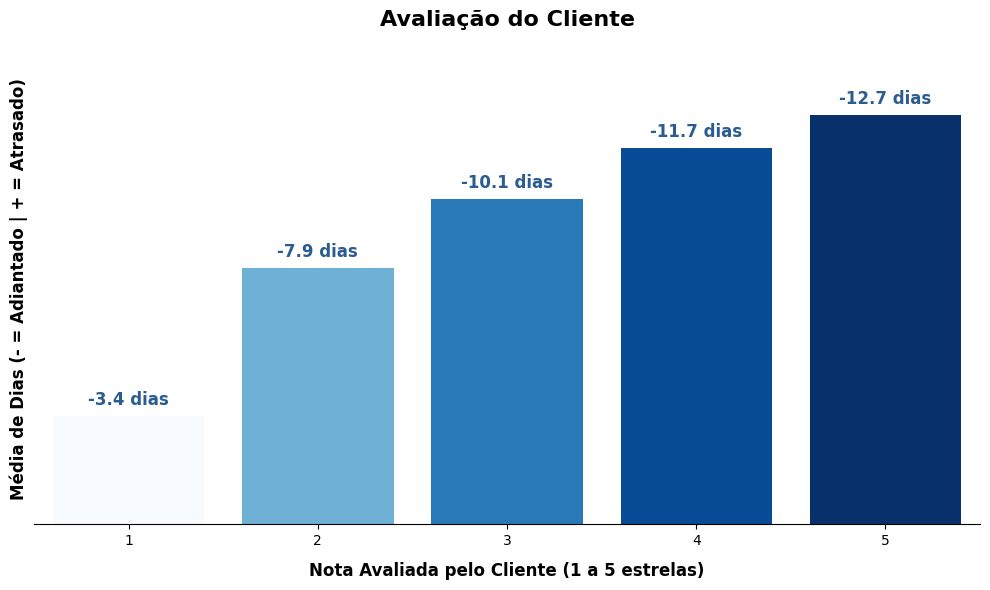

In [78]:
# 1. Leitura das tabelas orders e reviews
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_reviews = pd.read_csv('olist_order_reviews_dataset.csv')

# 2. Filtrando apenas pedidos entregues e que possuem avaliação
df_satisfacao = pd.merge(df_orders[df_orders['order_status'] == 'delivered'], df_reviews, on='order_id', how='inner')

# 3. Convertendo as datas para datetime
df_satisfacao['order_delivered_customer_date'] = pd.to_datetime(df_satisfacao['order_delivered_customer_date'])
df_satisfacao['order_estimated_delivery_date'] = pd.to_datetime(df_satisfacao['order_estimated_delivery_date'])

# 4. Calculando o "Dias de Atraso"
# Se o resultado for positivo (> 0), o produto chegou DEPOIS do prazo (Atrasou)
# Se o resultado for negativo (< 0), o produto chegou ANTES do prazo (Adiantado)
df_satisfacao['Dias_Atraso'] = (df_satisfacao['order_delivered_customer_date'] - df_satisfacao['order_estimated_delivery_date']).dt.total_seconds() / 86400

# 5. Agrupando para ver a média de dias de atraso para cada nota de 1 a 5 estrelas
media_atraso_por_nota = df_satisfacao.groupby('review_score')['Dias_Atraso'].mean().reset_index()

# Criação de uma coluna com valores absolutos (positivos) para as barras crescerem para cima
media_atraso_por_nota['Altura_Visual'] = media_atraso_por_nota['Dias_Atraso'].abs()

# 6. Criando o Gráfico de Colunas
plt.figure(figsize=(10, 6))

# Utilizando tonalidades de azul em proporção ao tamanho da barra.
norm = plt.Normalize(vmin=media_atraso_por_nota['Altura_Visual'].min(), vmax=media_atraso_por_nota['Altura_Visual'].max())
sm = plt.cm.ScalarMappable(cmap="Blues", norm=norm)
cores = [sm.to_rgba(val) for val in media_atraso_por_nota['Altura_Visual']]

ax = sns.barplot(data=media_atraso_por_nota, x='review_score', y='Altura_Visual', color='#2b5c8f')
for p, cor in zip(ax.patches, cores):
    p.set_facecolor(cor)

# 7. Adicionando os rótulos de dados
labels = [f"{val:+.1f} dias" for val in media_atraso_por_nota['Dias_Atraso']]
ax.bar_label(ax.containers[0], labels=labels, padding=5, fontsize=12, fontweight='bold', color='#2b5c8f')

# 8. Personalização do gráfico.
plt.title('Avaliação do Cliente', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Nota Avaliada pelo Cliente (1 a 5 estrelas)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Média de Dias (- = Adiantado | + = Atrasado)', fontsize=12, fontweight='bold')

# Limpeza
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.ylim(0, media_atraso_por_nota['Altura_Visual'].max() * 1.15)

plt.tight_layout()
plt.show()

##**Matriz de vendedores**

/tmp/ipykernel_2213/3241618554.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=perf_categorias, x='Perfil do Vendedor', y='Quantidade', palette=cores)


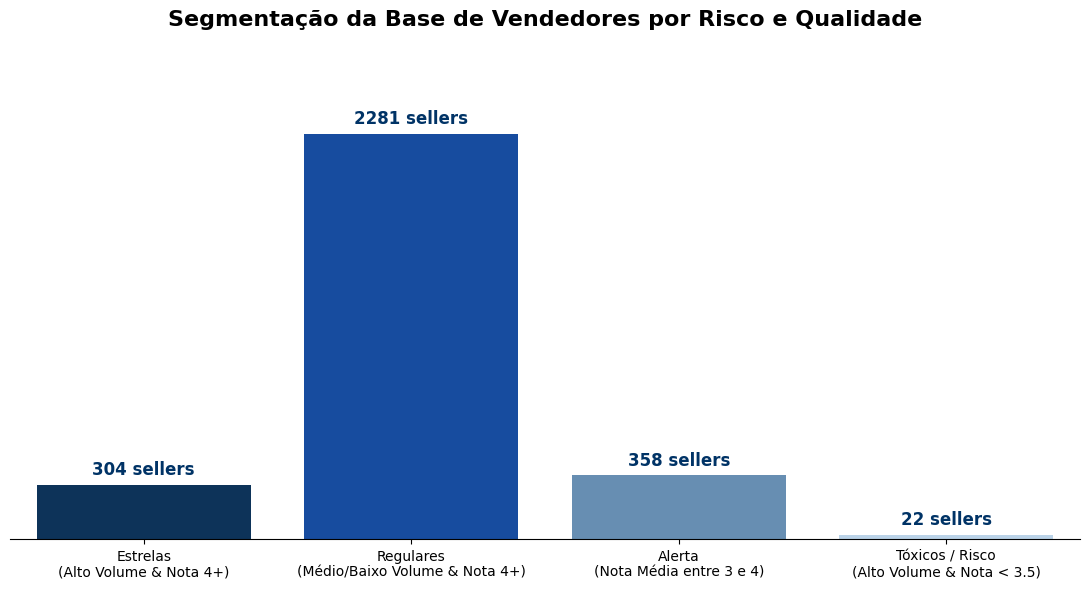

In [70]:
# 1. Leitura das tabelas items, reviews e orders.
df_items = pd.read_csv('olist_order_items_dataset.csv')
df_reviews = pd.read_csv('olist_order_reviews_dataset.csv')
df_orders = pd.read_csv('olist_orders_dataset.csv')

# 2. Relacionando as tabelas
df_vendedores = pd.merge(df_items[['order_id', 'seller_id']], df_reviews[['order_id', 'review_score']], on='order_id', how='inner')
df_vendedores = pd.merge(df_vendedores, df_orders[['order_id', 'order_status']], on='order_id', how='inner')
df_vendedores = df_vendedores[df_vendedores['order_status'] == 'delivered']

# 3. Agrupando por Vendedor (Volume e Nota Média)
matriz_vendedores = df_vendedores.groupby('seller_id').agg(
    Volume_Vendas=('order_id', 'count'),
    Nota_Media=('review_score', 'mean')
).reset_index()

# 4. Classificando os vendedores.
def categorizar_risco(row):
    limite_alto_volume = matriz_vendedores['Volume_Vendas'].quantile(0.85)

    if row['Volume_Vendas'] >= limite_alto_volume and row['Nota_Media'] < 3.5:
        return 'Tóxicos / Risco\n(Alto Volume & Nota < 3.5)'
    elif row['Volume_Vendas'] >= limite_alto_volume and row['Nota_Media'] >= 4.0:
        return 'Estrelas\n(Alto Volume & Nota 4+)'
    elif row['Nota_Media'] < 3.5:
        return 'Alerta\n(Nota Média entre 3 e 4)'
    else:
        return 'Regulares\n(Médio/Baixo Volume & Nota 4+)'

matriz_vendedores['Perfil_Vendedor'] = matriz_vendedores.apply(categorizar_risco, axis=1)

# 5. Contando quantos sellers existem em cada categoria de risco
perf_categorias = matriz_vendedores['Perfil_Vendedor'].value_counts().reset_index()
perf_categorias.columns = ['Perfil do Vendedor', 'Quantidade']

# Ordenação lógica para o gráfico
ordem_perfis = [
    'Estrelas\n(Alto Volume & Nota 4+)',
    'Regulares\n(Médio/Baixo Volume & Nota 4+)',
    'Alerta\n(Nota Média entre 3 e 4)',
    'Tóxicos / Risco\n(Alto Volume & Nota < 3.5)'
]
perf_categorias['Perfil do Vendedor'] = pd.Categorical(perf_categorias['Perfil do Vendedor'], categories=ordem_perfis, ordered=True)
perf_categorias = perf_categorias.sort_values('Perfil do Vendedor')

# 6. Desenhando o Gráfico de Colunas Executivo
plt.figure(figsize=(11, 6))

# Utilizando tonalidades de azul em proporção a valores.
cores = ['#003366', '#0047B6', '#5A8EBF', '#B3D4F0']
ax = sns.barplot(data=perf_categorias, x='Perfil do Vendedor', y='Quantidade', palette=cores)

# 7. Rótulos de dados no topo de cada coluna
for container in ax.containers:
    ax.bar_label(container, fmt='%d sellers', padding=5, fontsize=12, fontweight='bold', color='#003366')

# 8. Personalização e Limpeza
plt.title('Segmentação da Base de Vendedores por Risco e Qualidade', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('')
plt.ylabel('')

ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)

# Asterisco (*) adicionado para evitar erro de sintaxe
plt.ylim(0, perf_categorias['Quantidade'].max() * 1.2)

plt.tight_layout()
plt.show()